# A2 · The hospital simulator

**Goal:** build the hidden rule, generate 8 months of visits, and check the simulated hospital behaves like a real OPD *before* we trust it.

1. Write `expected_minutes` and `sample_noise` in [slotpred/world.py](../slotpred/world.py) (`TODO(you)`)
2. Run the tests until they pass
3. Generate the data
4. Sanity checks (given)
5. **The oracle** (`TODO(you)`): the best score any model could get

⚠️ We look only at the clean `world` here. The messy export (`raw`) is for A3, so don't explore it yet.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from slotpred.config import ROOT, TEST_START
from slotpred import world as w

## Concept: the noise, visualised

How a symmetric bell curve Z becomes right-skewed noise e^Z, and why the 80th percentile carries straight across (0.196 → e^0.196 = 1.217). Explained in [notes/A02-simulator.md](../notes/A02-simulator.md). This cell doesn't need your TODOs, so it runs before the tests pass.

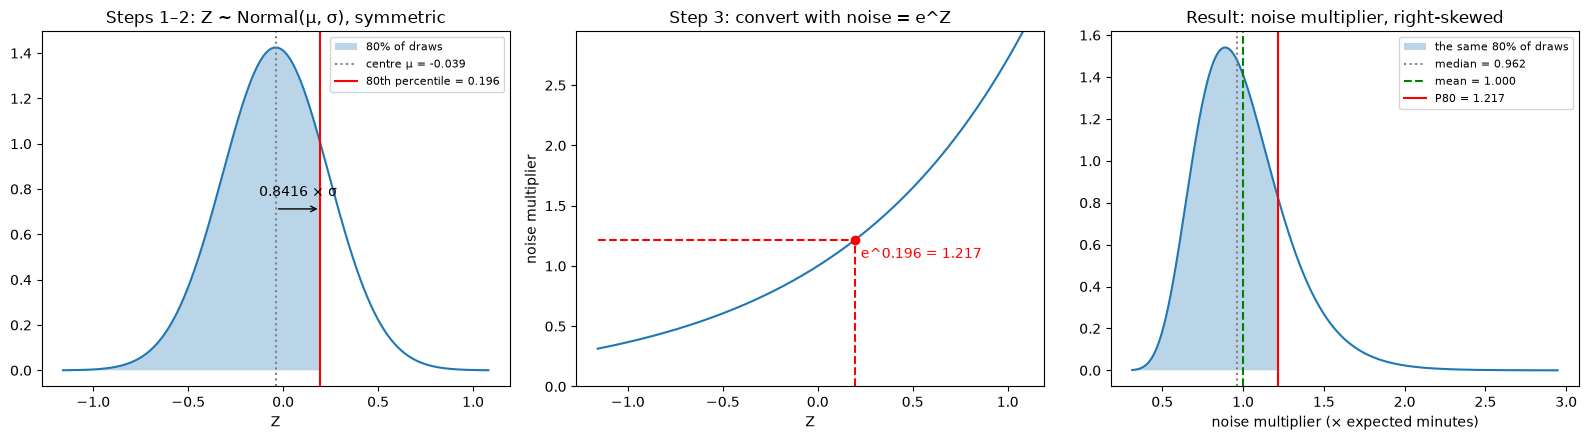

simulated mean   1.000   (expect 1.000)
simulated median 0.962   (expect 0.962)
simulated P80    1.218   (expect 1.217)


In [2]:
from scipy.stats import norm

sigma = w.NOISE_SIGMA
mu = -sigma**2 / 2                 # -0.039: makes the noise average exactly 1
z80 = norm.ppf(0.8)                # 0.8416, the z-score for 80%
q80_Z = mu + z80 * sigma           # 0.196, the 80th percentile of Z
q80_noise = np.exp(q80_Z)          # 1.217, the 80th percentile of the noise

z = np.linspace(mu - 4 * sigma, mu + 4 * sigma, 500)
pdf_z = norm.pdf(z, mu, sigma)
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. Z is a symmetric bell curve
ax1.plot(z, pdf_z)
ax1.fill_between(z, pdf_z, where=z <= q80_Z, alpha=0.3, label="80% of draws")
ax1.axvline(mu, ls=":", color="grey", label=f"centre μ = {mu:.3f}")
ax1.axvline(q80_Z, color="red", label=f"80th percentile = {q80_Z:.3f}")
ax1.annotate("", xy=(q80_Z, pdf_z.max() * 0.5), xytext=(mu, pdf_z.max() * 0.5), arrowprops=dict(arrowstyle="->"))
ax1.text((mu + q80_Z) / 2, pdf_z.max() * 0.54, "0.8416 × σ", ha="center")
ax1.set_title("Steps 1–2: Z ~ Normal(μ, σ), symmetric"); ax1.set_xlabel("Z"); ax1.legend(fontsize=8)

# 2. The conversion e^Z: 0.196 on the x-axis becomes 1.217 on the y-axis
ax2.plot(z, np.exp(z))
ax2.plot([q80_Z, q80_Z], [0, q80_noise], "r--"); ax2.plot([z.min(), q80_Z], [q80_noise, q80_noise], "r--")
ax2.scatter([q80_Z], [q80_noise], color="red", zorder=3)
ax2.text(q80_Z + 0.03, q80_noise - 0.15, f"e^{q80_Z:.3f} = {q80_noise:.3f}", color="red")
ax2.set_ylim(0, np.exp(z.max())); ax2.set_title("Step 3: convert with noise = e^Z")
ax2.set_xlabel("Z"); ax2.set_ylabel("noise multiplier")

# 3. The noise is right-skewed
x = np.exp(z)
pdf_x = pdf_z / x                  # density after the change of variable (dz/dx = 1/x)
ax3.plot(x, pdf_x)
ax3.fill_between(x, pdf_x, where=x <= q80_noise, alpha=0.3, label="the same 80% of draws")
ax3.axvline(np.exp(mu), ls=":", color="grey", label=f"median = {np.exp(mu):.3f}")
ax3.axvline(1.0, ls="--", color="green", label="mean = 1.000")
ax3.axvline(q80_noise, color="red", label=f"P80 = {q80_noise:.3f}")
ax3.set_title("Result: noise multiplier, right-skewed"); ax3.set_xlabel("noise multiplier (× expected minutes)")
ax3.legend(fontsize=8)
plt.tight_layout(); plt.show()

# Check the maths with a million random draws
draws = np.exp(np.random.default_rng(0).normal(mu, sigma, 1_000_000))
print(f"simulated mean   {draws.mean():.3f}   (expect 1.000)")
print(f"simulated median {np.median(draws):.3f}   (expect {np.exp(mu):.3f})")
print(f"simulated P80    {np.quantile(draws, 0.8):.3f}   (expect {q80_noise:.3f})")

## Step 2 - run the tests

Red means not right yet; read the failing test's name and message. Green means done. Rerun this cell after each edit to `world.py`.

In [4]:
!"{sys.executable}" -m pytest "{ROOT / 'tests' / 'test_world.py'}" -q

...............                                                          [100%]
15 passed in 0.18s


## Step 3 - generate the data

In [5]:
from slotpred import simulate as sim

world, raw = sim.main()
world.head()

43,747 visits, 2026-01-01 .. 2026-08-31
wrote C:\Users\siddh\Documents\slot-prediction-model\data\raw_emr_export.csv (43,922 rows) and C:\Users\siddh\Documents\slot-prediction-model\data\_hidden_truth.csv


,appointment_id,date,weekday,slot_time,clinic,doctor,department,doctor_speed,patient_id,patient_name,...,interpreter,visit_type,prior_reports,teleconsult,expected_minutes,noise,actual_minutes,check_in,consult_start,consult_end
0,A000000,2026-01-01,3,09:15,HSR,Divya Rao,Dermatology,0.9,P05281,Pooja,...,False,new,0,False,9.4500,0.548804,5.186199,2026-01-01 08:58:09.435399534,2026-01-01 09:23:43.361751996,2026-01-01 09:28:54.533714898
1,A000001,2026-01-01,3,09:30,HSR,Divya Rao,Dermatology,0.9,P01610,Krishna,...,False,new,1,False,10.6785,1.252700,13.376959,2026-01-01 09:26:35.174380284,2026-01-01 09:38:28.552633092,2026-01-01 09:51:51.170149806
2,A000002,2026-01-01,3,10:30,HSR,Divya Rao,Dermatology,0.9,P00193,Sunil,...,False,new,1,False,10.1700,1.025517,10.429503,2026-01-01 10:14:19.315481892,2026-01-01 10:31:53.431114920,2026-01-01 10:42:19.201308630
3,A000003,2026-01-01,3,11:15,HSR,Divya Rao,Dermatology,0.9,P00462,Arun,...,False,follow-up,1,False,6.5700,0.725305,4.765253,2026-01-01 10:57:09.449749308,2026-01-01 11:16:10.728884700,2026-01-01 11:20:56.644067034
4,A000004,2026-01-01,3,11:30,HSR,Divya Rao,Dermatology,0.9,P00483,Om,...,False,follow-up,0,False,5.4000,1.080740,5.835994,2026-01-01 11:13:41.062800894,2026-01-01 11:30:54.309381774,2026-01-01 11:36:44.469037140


## Step 4 - sanity checks

### 4a. Is it right-skewed, like real consults?

mean 13.5  median 11.8  P80 18.3  max 102


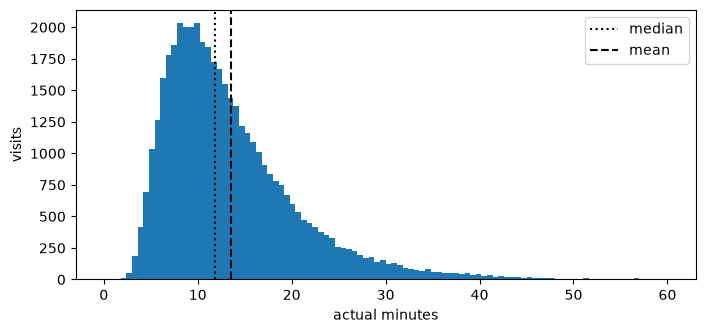

In [6]:
y = world["actual_minutes"]
print(f"mean {y.mean():.1f}  median {y.median():.1f}  P80 {y.quantile(0.8):.1f}  max {y.max():.0f}")

plt.figure(figsize=(8, 3.5))
plt.hist(y, bins=100, range=(0, 60))
plt.axvline(y.median(), color="black", linestyle=":", label="median")
plt.axvline(y.mean(), color="black", linestyle="--", label="mean")
plt.xlabel("actual minutes"); plt.ylabel("visits"); plt.legend(); plt.show()

### 4b. Do departments and visit types come out in the right order?

Compare with the base table. The medians will differ a little: reports, interpreters, age and noise all shift them.

In [7]:
world.pivot_table(index="department", columns="visit_type", values="actual_minutes", aggfunc="median").round(1)

visit_type,follow-up,new,review
department,,,
Cardiology,9.3,22.7,15.8
Dermatology,7.0,11.6,10.7
ENT,7.0,12.3,10.6
General Medicine,7.3,13.0,12.0
Gynaecology,10.2,18.9,15.4
Neurology,12.7,28.3,18.8
Orthopaedics,8.1,14.5,12.7
Paediatrics,9.6,17.3,13.6


### 4c. Can we see the drift?

Weekly median for Dermatology vs everyone else. Something should change on 1 July.

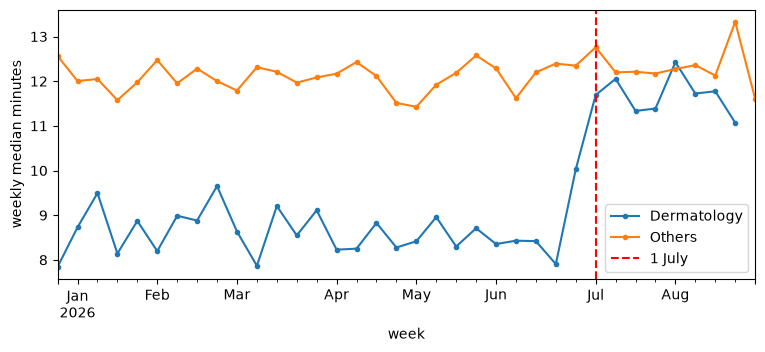

In [8]:
weekly = (world.assign(week=pd.to_datetime(world["date"]).dt.to_period("W").dt.start_time,
                       group=np.where(world["department"] == "Dermatology", "Dermatology", "Others"))
              .groupby(["week", "group"])["actual_minutes"].median().unstack())

weekly.plot(figsize=(9, 3.5), marker=".")
plt.axvline(pd.Timestamp(TEST_START), color="red", linestyle="--", label="1 July") # type: ignore
plt.ylabel("weekly median minutes"); plt.legend(); plt.show()

## Step 5 - TODO(you): the oracle

The oracle knows the hidden rule exactly (`expected_minutes`), but not the noise. Its best predictions are:

- **P50** = expected × e^(−σ²/2)
- **P80** = expected × e^(−σ²/2 + 0.8416·σ)

On the **test period** (`date >= TEST_START`), compute:

| | Oracle | Fixed 15-min slot (today's rule) |
|---|---|---|
| MAE (P50 guess vs actual) | ? | use 15 as the guess |
| Coverage (actual ≤ P80) | ? | actual ≤ 15 |
| Average idle minutes (slot − actual, when positive) | ? | ? |

For the oracle's slot, use P80 **rounded up to 5 minutes** (`np.ceil(p80 / 5) * 5`). Use `w.NOISE_SIGMA` for σ.

In [11]:
from scipy.stats import norm
from slotpred.config import Q_CANDIDATES

test = world[world["date"] >= TEST_START].copy()
y = test["actual_minutes"]
sigma = w.NOISE_SIGMA

def summarise(guess, slot):
    guess = pd.Series(guess, index=y.index)
    slot = pd.Series(slot, index=y.index)
    return {
        "MAE (min)": (y - guess).abs().mean(),
        "overrun rate (actual > slot)": (y > slot).mean(),
        "avg idle (min)": (slot - y).clip(lower=0).mean(),
        "avg overrun (min)": (y - slot).clip(lower=0).mean(),
        "avg slot (min)": slot.mean(),
    }

# The oracle knows the RULE (expected_minutes), never the noise (so never actual_minutes)
p50 = test["expected_minutes"] * np.exp(-sigma**2 / 2)

results = {"Fixed 15 min": summarise(15, 15)}
for q in Q_CANDIDATES:
    z = norm.ppf(q)                                                   # 0.44 for P67, 0.67 for P75, 0.84 for P80
    p_q = test["expected_minutes"] * np.exp(-sigma**2 / 2 + z * sigma)
    results[f"Oracle P{round(q * 100)}, exact"] = summarise(p50, p_q)
    results[f"Oracle P{round(q * 100)}, rounded to 5"] = summarise(p50, np.ceil(p_q / 5) * 5)

display(pd.DataFrame(results).round(3))

overrun_15 = (test.assign(overran=y > 15)
                  .groupby(["department", "visit_type"])["overran"].mean()
                  .unstack().round(2))
display(overrun_15)

,Fixed 15 min,"Oracle P67, exact","Oracle P67, rounded to 5","Oracle P75, exact","Oracle P75, rounded to 5","Oracle P80, exact","Oracle P80, rounded to 5"
MAE (min),5.765,3.081,3.081,3.081,3.081,3.081,3.081
overrun rate (actual > slot),0.352,0.336,0.170,0.252,0.125,0.203,0.098
avg idle (min),3.368,2.265,4.240,2.997,5.115,3.600,5.767
avg overrun (min),2.396,1.102,0.574,0.802,0.413,0.628,0.316
avg slot (min),15.000,15.191,17.694,16.222,18.730,17.000,19.480


visit_type,follow-up,new,review
department,,,
Cardiology,0.09,0.89,0.55
Dermatology,0.07,0.41,0.40
ENT,0.03,0.30,0.16
General Medicine,0.02,0.37,0.29
Gynaecology,0.10,0.78,0.52
Neurology,0.28,0.98,0.80
Orthopaedics,0.04,0.49,0.33
Paediatrics,0.15,0.72,0.45


## Step 5b - see the oracle

(a) one visit's spread of outcomes and where each quantile books the slot; (b) the trade-off between running late and idle time for every q, exact vs rounded; (c) who today's fixed 15-minute slot hurts.

In [ ]:
# --- Step 5b: see the oracle (three pictures) ---------------------------------
from scipy.stats import norm
from slotpred.config import Q_CANDIDATES

sigma = w.NOISE_SIGMA
mu = -sigma**2 / 2
test = world[world["date"] >= TEST_START].copy()
y = test["actual_minutes"]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

# (a) ONE visit: Siddhant, new consult, Dr Deepak, Monday 10:30, HSR, 2 reports -> expected 13.7 min
ax = axes[0]
m = 13.7
x = np.linspace(4, 35, 600)
pdf = norm.pdf(np.log(x / m), mu, sigma) / x                     # density of actual minutes for this visit
ax.plot(x, pdf, color="black")
median = m * np.exp(mu)
ax.axvline(median, ls=":", color="grey", label=f"oracle P50 = {median:.1f} (its guess)")
colours = {0.67: "tab:green", 0.75: "tab:orange", 0.80: "tab:red"}
for q in Q_CANDIDATES:
    pq = m * np.exp(mu + norm.ppf(q) * sigma)
    ax.axvline(pq, color=colours[q], label=f"P{round(q*100)} = {pq:.1f} -> slot {np.ceil(pq/5)*5:.0f}")
p80 = m * np.exp(mu + norm.ppf(0.8) * sigma)
ax.fill_between(x, pdf, where=x > p80, color="tab:red", alpha=0.25, label="runs past P80 (20% of visits)")
ax.set_title("One visit type: the oracle still can't know which end it lands")
ax.set_xlabel("actual minutes"); ax.set_yticks([]); ax.legend(fontsize=8)

# (b) The trade-off: every q from 0.50 to 0.95, exact slot vs slot rounded up to 5
ax = axes[1]
qs = np.linspace(0.50, 0.95, 46)
for rounded, style in [(False, "-"), (True, "--")]:
    pts = []
    for q in qs:
        slot = test["expected_minutes"] * np.exp(mu + norm.ppf(q) * sigma)
        if rounded:
            slot = np.ceil(slot / 5) * 5
        pts.append(((slot - y).clip(lower=0).mean(), (y > slot).mean()))
    pts = np.array(pts)
    ax.plot(pts[:, 0], pts[:, 1], style, color="tab:blue", label="rounded up to 5 min" if rounded else "exact slot")
    for q in Q_CANDIDATES:
        i = np.argmin(abs(qs - q))
        ax.scatter(*pts[i], color=colours[q], zorder=3)
        ax.annotate(f"P{round(q*100)}", pts[i], textcoords="offset points", xytext=(6, 4), fontsize=8)
ax.scatter((15 - y).clip(lower=0).mean(), (y > 15).mean(), marker="X", s=120, color="black", zorder=3, label="fixed 15 min (today)")
ax.set_xlabel("average idle minutes per visit (doctor waiting)")
ax.set_ylabel("overrun rate (share of visits running late)")
ax.set_title("Trade-off: less late means more idle")
ax.legend(fontsize=8); ax.grid(alpha=0.3)

# (c) Who the fixed 15-minute slot hurts
ax = axes[2]
overrun_15 = (test.assign(overran=y > 15).groupby(["department", "visit_type"])["overran"].mean()
                  .unstack()[["follow-up", "review", "new"]])
im = ax.imshow(overrun_15.values, cmap="RdYlGn_r", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(3), overrun_15.columns); ax.set_yticks(range(len(overrun_15)), overrun_15.index)
for i in range(overrun_15.shape[0]):
    for j in range(3):
        ax.text(j, i, f"{overrun_15.values[i, j]:.0%}", ha="center", va="center", fontsize=8)
ax.set_title("Fixed 15 min: share of visits that run late")
plt.colorbar(im, ax=ax, fraction=0.04)

plt.tight_layout()
plt.show()


## Questions - answers

1. **What's the oracle's MAE?**

   *My first answer:* "the minimum slot booking time below which no slot should be allowed" - **not quite.**

   **3.08 minutes.** It's not a slot length; it's the smallest **average prediction error** any model can reach. The oracle knows the hidden rule perfectly but can't know the noise (a worried patient, an unexpected finding), so its typical guess is still about 3 minutes off. Closed form: MAE = expected x (2*Phi(sigma) - 1) = 0.22 x expected; average expected minutes 13.97, so 0.22 x 13.97 = 3.08. LightGBM will score **at least 3.08**; fixed 15 scores 5.77.

2. **Is the oracle's coverage close to 80%?**

   With the **exact** P80 slot: 79.7%, so yes (80% up to sampling). With the slot **rounded up to 5 min**: 90.2% (only 9.8% run late). Rounding up adds 2.5 minutes to each slot on average, which buys extra coverage at the price of idle time (3.6 -> 5.8 min). Consequence for the PO: on a 5-minute grid, a **lower q already gives the target**. Rounded P67 means only 17% run late, inside "2 in 10".

3. **Fixed 15 vs the oracle.**

   Fixed 15: **35% run late**, 2.4 late minutes and 3.4 idle minutes per visit. It's too short for long visits (Neurology new 98% late, Cardiology new 89%, Gynaecology new 78%, Paediatrics new 72%) and too long for short ones (General Medicine follow-up 2% late, about 7 idle minutes). **One slot fits nobody.** The exact oracle P67 books almost the same total time (15.2 min on average) yet halves the late minutes (1.1 vs 2.4) and cuts idle time (2.3 vs 3.4): prediction doesn't add time, it **moves it to the visits that need it**.

4. **Why P80 is about 27% above the median for every visit.**

   P80 / median = e^(mu + z*sigma) / e^(mu) = e^(z*sigma) = e^(0.8416 x 0.28) = 1.27. The expected minutes and mu cancel, so the *relative* margin depends only on sigma (multiplicative noise). In minutes it grows with the visit: a 10-min visit gets +2.7 min, a 30-min visit +8 min. For the PO's candidates: P75 -> +21%, P67 -> +13%.
